# Natural Language (Wikitext Variants)

In [1]:
import sys
sys.path.insert(0, "..")

from interpretability.utils import get_attention, plot_attention, plot_attention_per_head

## wikitext-nl

In [2]:
attn_nl = get_attention("wikitext_nl_model-1l-8h-512e")

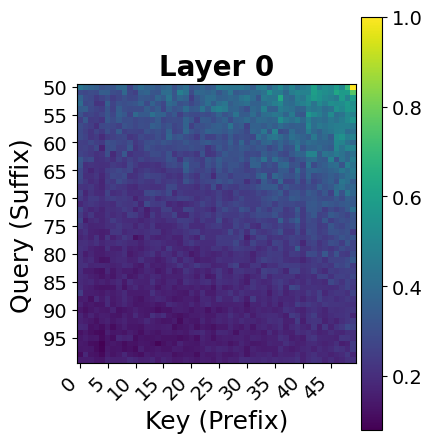

In [3]:
plot_attention(attn_nl, query_range=(50, 100), key_range=(0, 50), reduce="normalized_sum")

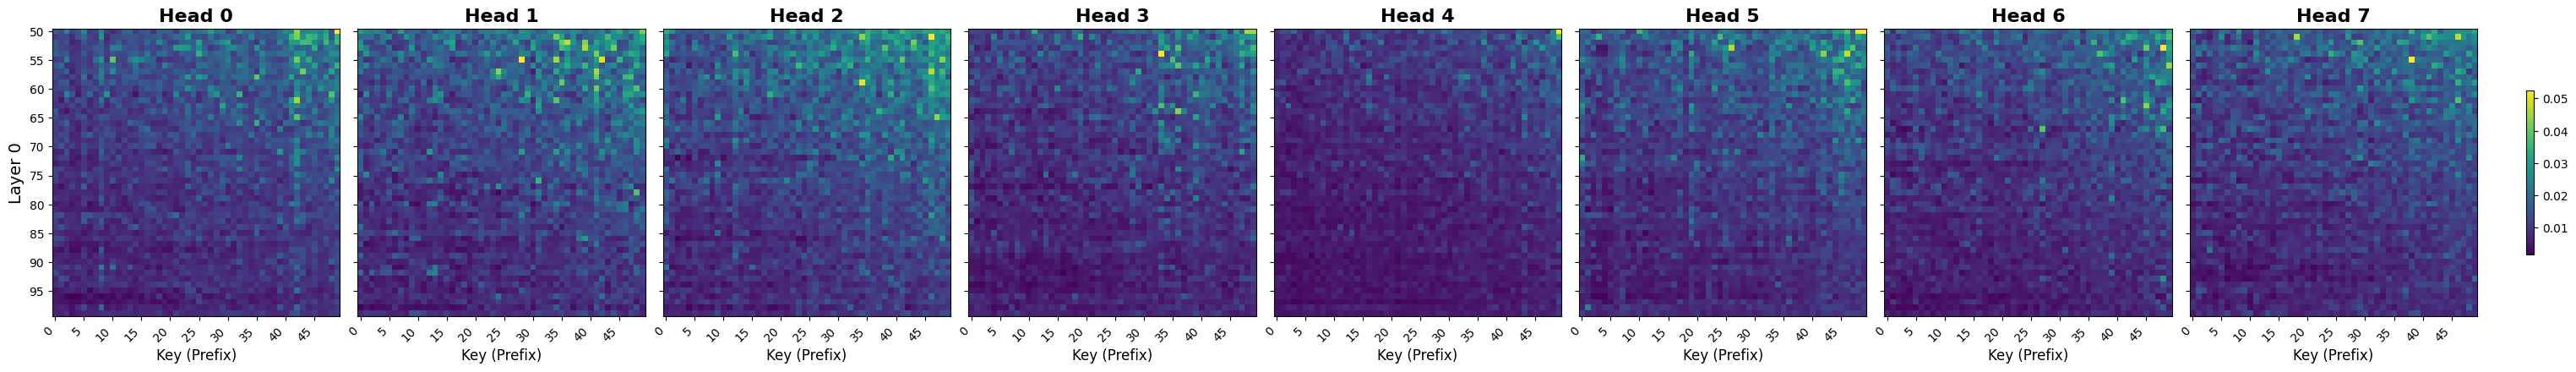

In [4]:
plot_attention_per_head(attn_nl)

## wikitext-translated

In [5]:
attn_translated = get_attention("wikitext_translated_model-1l-8h-512e")

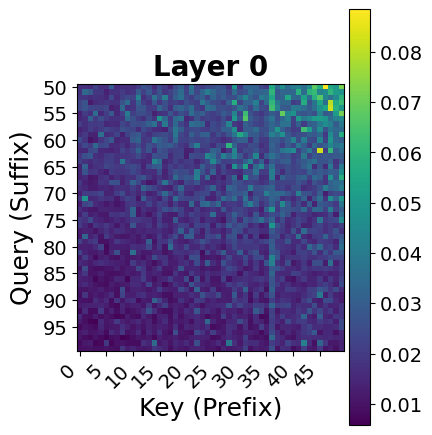

In [6]:
plot_attention(attn_translated)

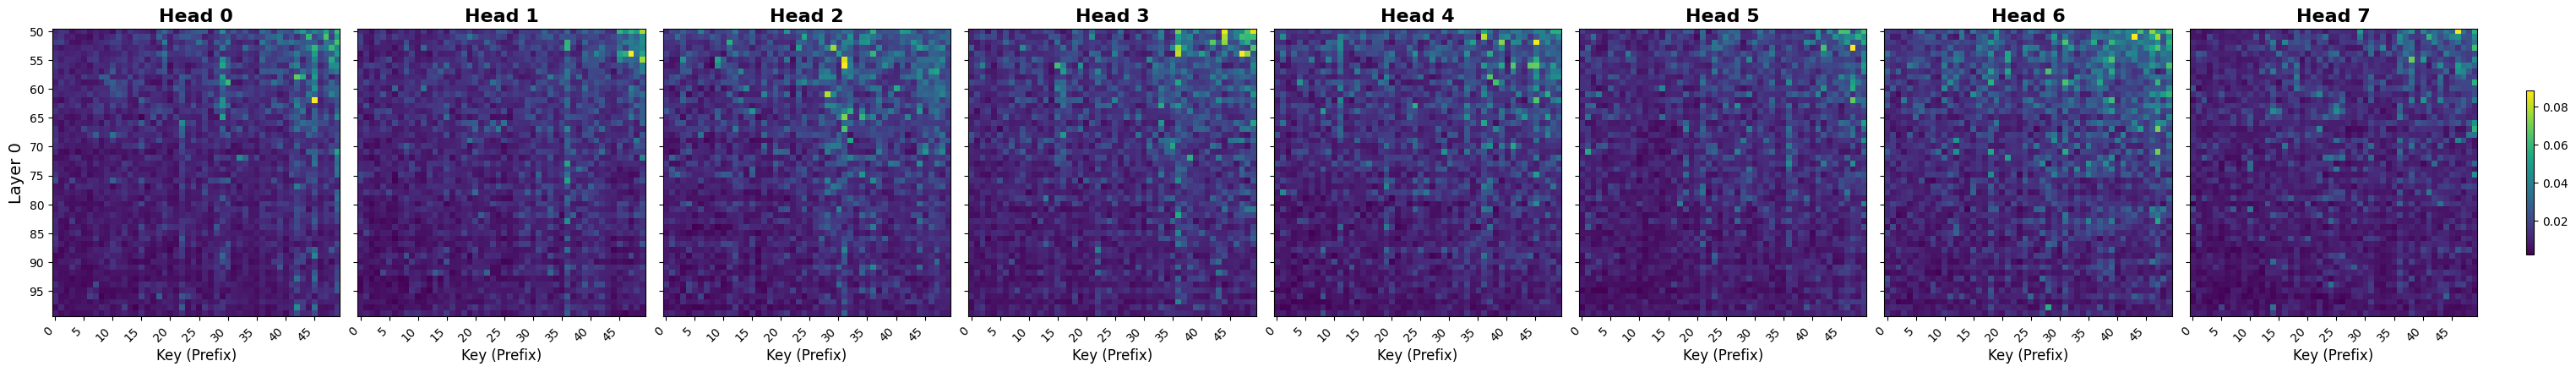

In [7]:
plot_attention_per_head(attn_translated)

## wikitext-translated-uid

In [8]:
attn_uid = get_attention("wikitext_translated_uid_model-1l-8h-512e")

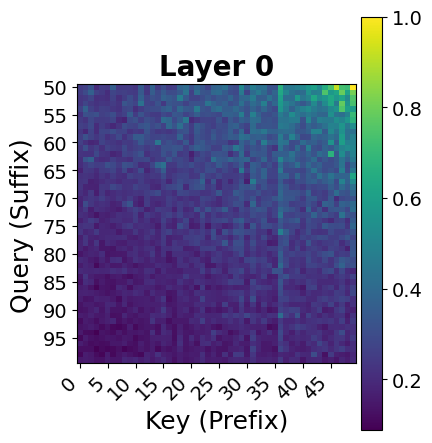

In [9]:
plot_attention(attn_uid, reduce="normalized_sum")

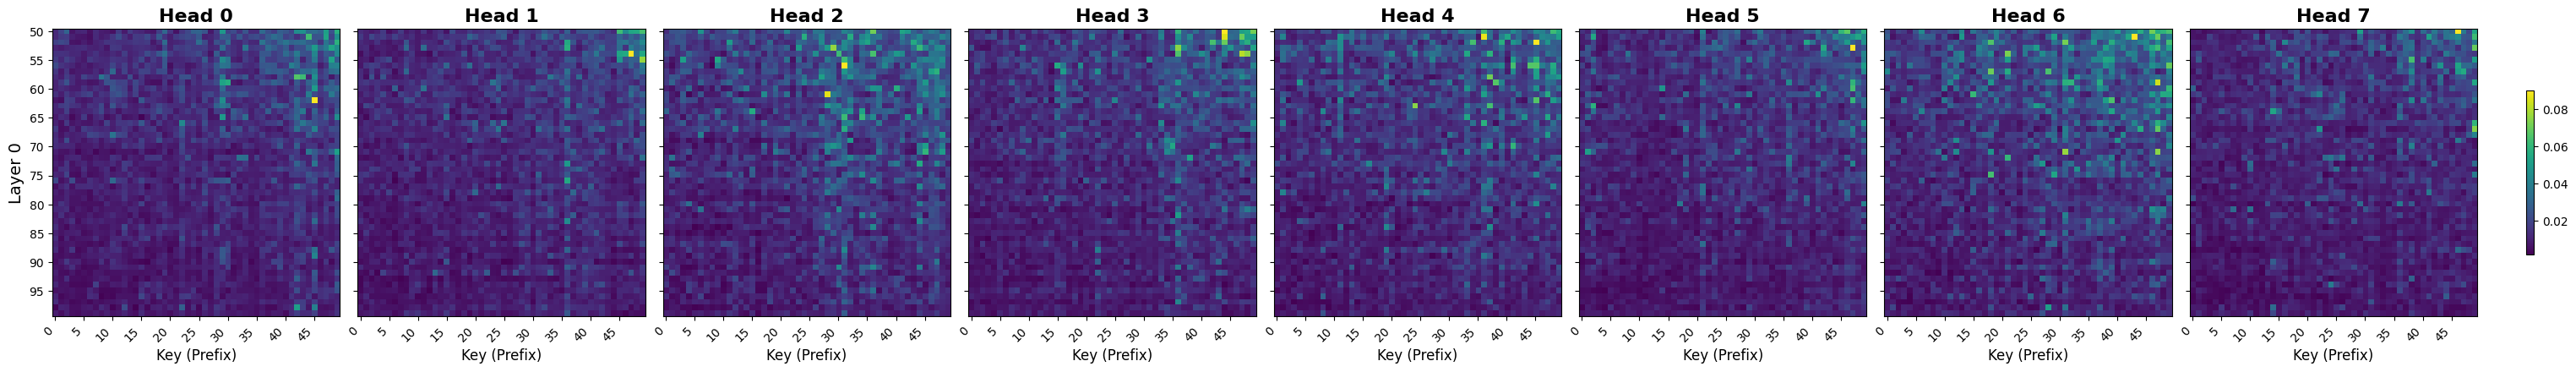

In [10]:
plot_attention_per_head(attn_uid)

wikitext translated 5 uids in prefix

In [11]:
attn_uid5 = get_attention("wikitext_translated_uid5_model-1l-8h-512e")

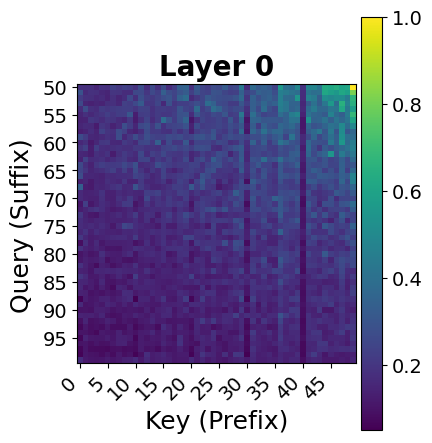

In [12]:
plot_attention(attn_uid5, reduce="normalized_sum")

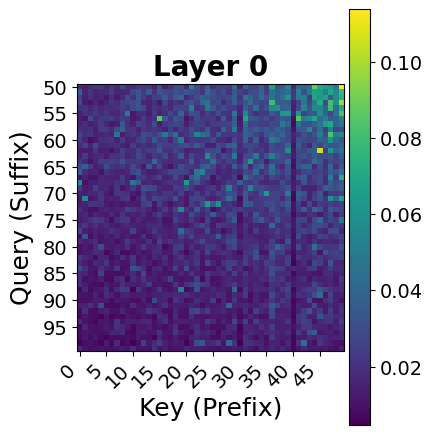

In [14]:
plot_attention(attn_uid5, reduce="max")

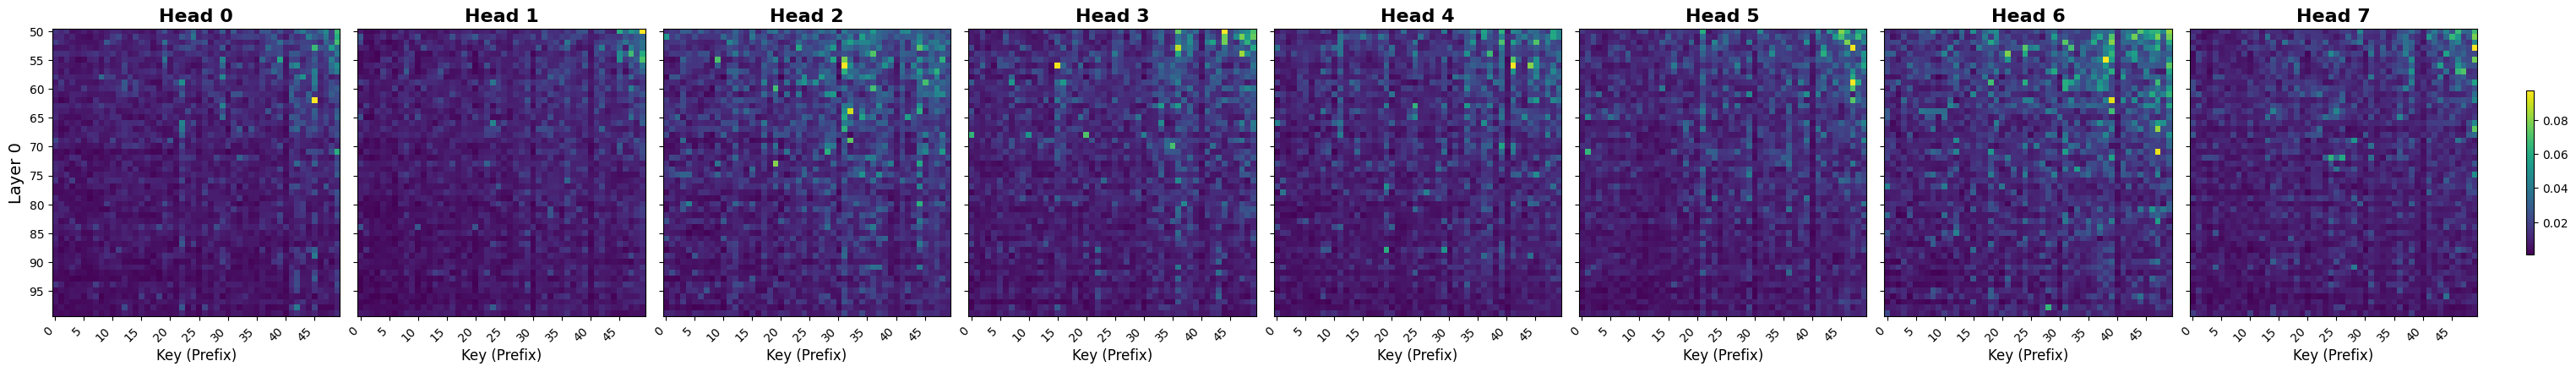

In [13]:
plot_attention_per_head(attn_uid5)

## Cross-variant comparison

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

variants = [
    ("wikitext-nl", attn_nl),
    ("wikitext-translated", attn_translated),
    ("wikitext-translated-uid", attn_uid),
]

q0, q1 = 50, 100
k0, k1 = 0, 50
layer_idx = 0

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True, constrained_layout=True)

for ax, (name, attn) in zip(axes, variants):
    n_heads = attn.shape[1]
    head_stack = np.stack(
        [attn[layer_idx, h, q0:q1, k0:k1].cpu().numpy() for h in range(n_heads)],
        axis=0,
    )
    img = head_stack.max(axis=0)
    im = ax.imshow(img, cmap="viridis", aspect="equal")
    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Key (Prefix)", fontsize=12)

axes[0].set_ylabel("Query (Suffix)", fontsize=12)
fig.colorbar(im, ax=axes, shrink=0.92, pad=0.02)
fig.suptitle(f"Layer {layer_idx} — max across heads", fontsize=14, fontweight="bold")
plt.show()